# Connected Fitness Performance Analytics
GSBA 594–42H

Can prepared workout histories predict scheduled-class performance beyond simple historical summaries? This release uses masked numeric indices, category codes and relative chronology. It does not attribute ownership of the source dataset. The original export, exact timestamps and inverse maps are excluded.

**Outcome distinction:** regression has the lowest later-period error, while the recent average wins development selection. The later comparison remains exploratory because earlier analysis exposed it.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image
from analyze_peloton import ROOT, run, load_data, split, NUMERIC, CATEGORICAL, FEATURES, TARGET

data, results, summary = run()
OUT = ROOT / "results"
print(summary)


             model  selected_by_development_cv  MAE_index  RMSE_index        R2  bias_index  MAE_improvement_vs_training_mean_percent
     Training mean                       False   0.629589    0.805708 -0.171260   -0.308091                                  0.000000
  Class group mean                       False   0.546754    0.704350  0.104894   -0.259192                                 13.156979
Recent 28-day mean                        True   0.595945    0.770518 -0.071183   -0.039221                                  5.343806
  Ridge regression                       False   0.542777    0.677837  0.171010    0.102364                                 13.788701
     Random forest                       False   0.746761    0.920718 -0.529507    0.179656                                -18.610866
{'model_rides': 420, 'development_rides': 331, 'evaluation_rides': 89, 'selected_by_development_cv': 'Recent 28-day mean', 'lowest_later_period_MAE': 'Ridge regression', 'evaluation_status': 'Expl

## Model variables
Seven numeric predictors cover scheduled duration/start time, elapsed time, prior exercise minutes/days and recent average output. Three categorical predictors cover class type and coded instructor/weekday. README lists each exact column and definition.

All numeric data are released on masked scales. Fitted models still impute and standardize within their own training folds. The target is output_index, not original power units. ride_id and day_index support identification/grouped chronological splitting and are not additional predictors.

In [2]:
print("Target:", TARGET)
print("Numeric predictors:", NUMERIC)
print("Categorical predictors:", CATEGORICAL)
display(data.head())
display(data[FEATURES].isna().sum().rename("missing_count").to_frame())


Target: output_index
Numeric predictors: ['planned_duration_index', 'start_time_index', 'elapsed_time_index', 'exercise_7d_index', 'exercise_28d_index', 'exercise_days_7d_index', 'recent_output_index']
Categorical predictors: ['class_type', 'instructor_code', 'weekday_code']


,ride_id,day_index,planned_duration_index,start_time_index,elapsed_time_index,exercise_7d_index,exercise_28d_index,exercise_days_7d_index,recent_output_index,class_type,instructor_code,weekday_code,output_index
0,R0001,0,-1.062257,2.751143,-2.111507,-1.973373,-2.172897,-2.091832,NaN,Beginner,I020,D4,-0.601167
1,R0002,1,-1.062257,-2.423419,-2.109959,-1.747611,-2.090128,-1.602157,-0.890181,Low Impact,I008,D5,-0.408491
2,R0003,1,-0.509434,2.751143,-2.109959,-1.747611,-2.090128,-1.602157,-0.890181,Music,I014,D5,0.458552
3,R0004,3,-0.509434,2.751143,-2.106865,-1.425095,-1.971886,-1.112481,-0.432575,Music,I011,D7,0.121369
4,R0005,4,-1.062257,3.268599,-2.105317,-1.199334,-1.889117,-0.622806,-0.321787,Music,I017,D1,0.795735


,missing_count
planned_duration_index,0
start_time_index,0
elapsed_time_index,0
exercise_7d_index,0
exercise_28d_index,0
exercise_days_7d_index,0
recent_output_index,10
class_type,0
instructor_code,0
weekday_code,0


## Temporal validation
The first 80% of distinct days form development. Three expanding time splits choose the lowest mean MAE candidate using fixed settings. Same-day rides stay together. Historical features exclude the current day, but can incorporate completed earlier evaluation days. The fitted parameters remain fixed during each window.

In [3]:
train, evaluation = split(data)
print("Development rides:", len(train), "Later rides:", len(evaluation))
display(pd.read_csv(OUT / "development_cv_summary.csv"))
display(pd.read_csv(OUT / "development_cv_folds.csv"))


Development rides: 331 Later rides: 89


,model,mean,std
0,Recent 28-day mean,0.587344,0.022958
1,Class group mean,0.886095,0.275975
2,Training mean,0.973094,0.672567
3,Random forest,1.066899,0.680576
4,Ridge regression,1.363784,1.504068


,fold,model,train_rides,validation_rides,train_end_day,validation_start_day,validation_end_day,MAE_index,RMSE_index,R2,bias_index
0,1,Training mean,90,77,240,241,1692,1.748752,1.890146,-3.624472,1.673349
1,1,Class group mean,90,77,240,241,1692,1.204735,1.353600,-1.371659,1.150278
2,1,Recent 28-day mean,90,77,240,241,1692,0.612124,0.927904,-0.114493,0.122890
3,1,Ridge regression,90,77,240,241,1692,3.098097,3.491497,-14.779557,3.081195
4,1,Random forest,90,77,240,241,1692,1.852564,1.996825,-4.161209,1.844187
5,2,Training mean,167,78,1692,1693,1820,0.618617,0.779118,-0.257804,0.352729
6,2,Class group mean,167,78,1692,1693,1820,0.730501,0.918920,-0.749692,0.536821
7,2,Recent 28-day mean,167,78,1692,1693,1820,0.583111,0.721146,-0.077588,-0.102657
8,2,Ridge regression,167,78,1692,1693,1820,0.417003,0.558718,0.353167,0.061520
9,2,Random forest,167,78,1692,1693,1820,0.658852,0.846141,-0.483515,-0.530322


## Final key results
- Ridge regression has the lowest later-period MAE, about 0.543 output-index units.
- Random forest has higher later error, about 0.747, despite greater complexity.
- The recent 28-day mean wins development selection and remains the selected method under that rule.
- Different windows produce different comparisons. No universal superiority or product-effect claim follows.

The output index changes MAE/RMSE units. R² and percentage improvements support comparisons across the revision. Small refitted forest differences reflect numerical ties; MASKING_CHECK.md reports the verification.

,model,selected_by_development_cv,MAE_index,RMSE_index,R2,bias_index,MAE_improvement_vs_training_mean_percent
0,Training mean,False,0.6296,0.8057,-0.1713,-0.3081,0.0000
1,Class group mean,False,0.5468,0.7043,0.1049,-0.2592,13.1570
2,Recent 28-day mean,True,0.5959,0.7705,-0.0712,-0.0392,5.3438
3,Ridge regression,False,0.5428,0.6778,0.1710,0.1024,13.7887
4,Random forest,False,0.7468,0.9207,-0.5295,0.1797,-18.6109


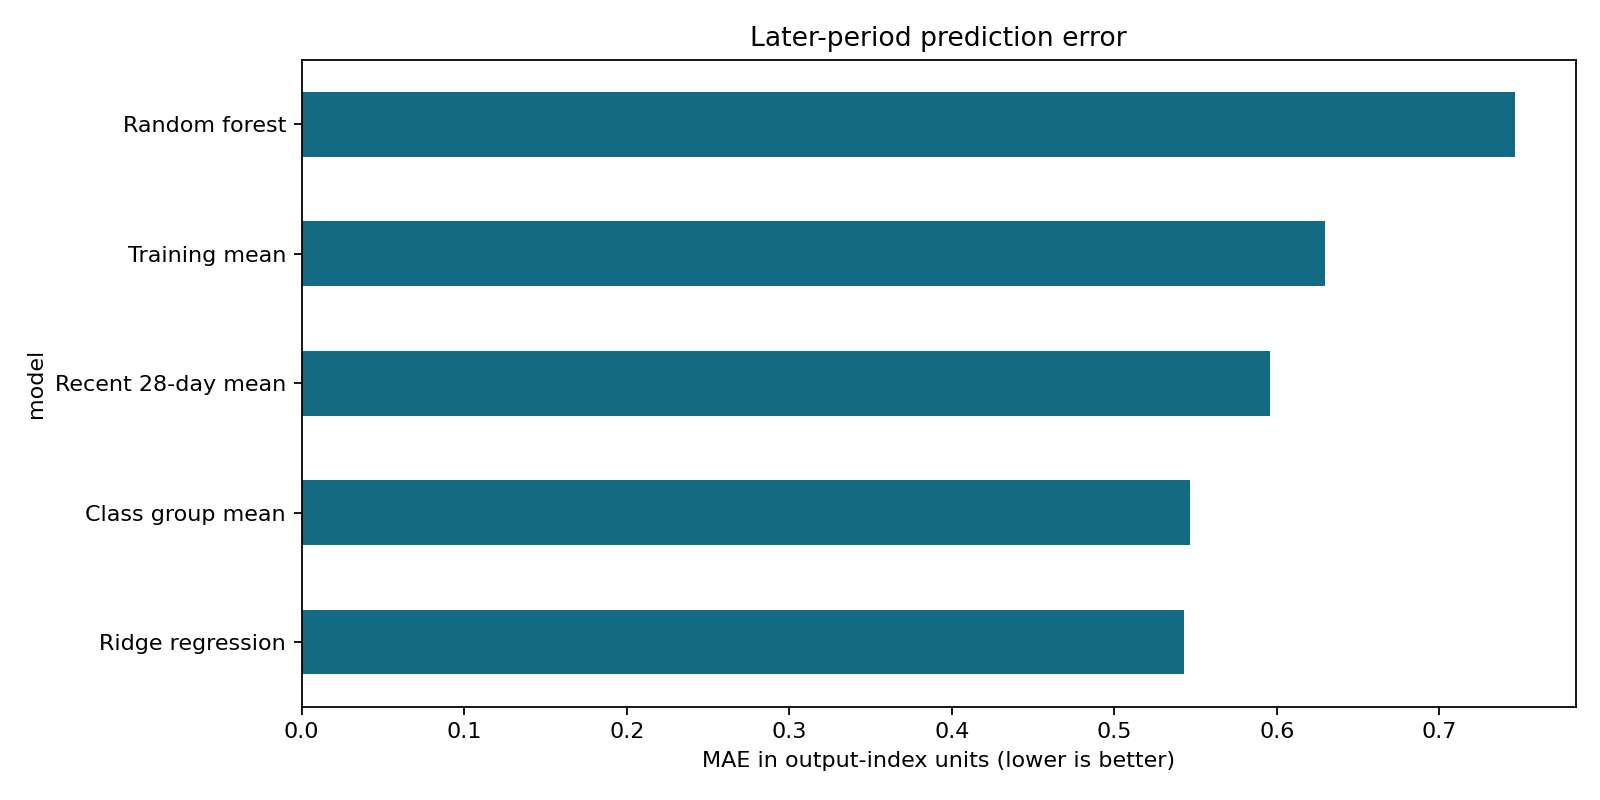

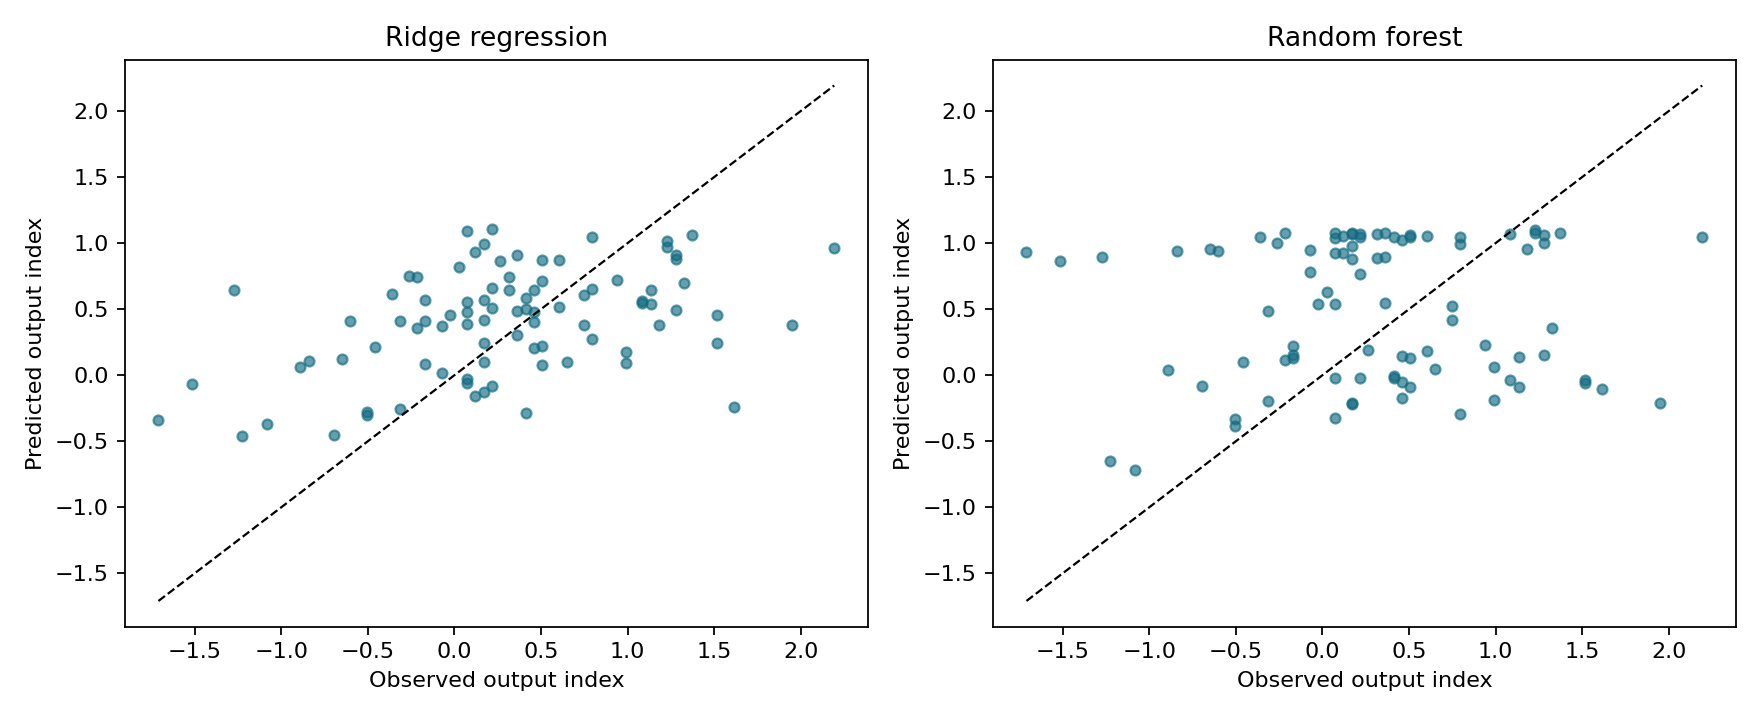

In [4]:
display(results.round(4))
display(Image(filename=str(OUT / "model_errors.png")))
display(Image(filename=str(OUT / "prediction_comparison.png")))


## Descriptive trends and robustness
Indexed descriptive series preserve shape but omit original measurement scales and dates. Their series-wide descriptive normalization does not enter any predictive model. Sensitivity flags identify predefined subsets without adding model inputs.

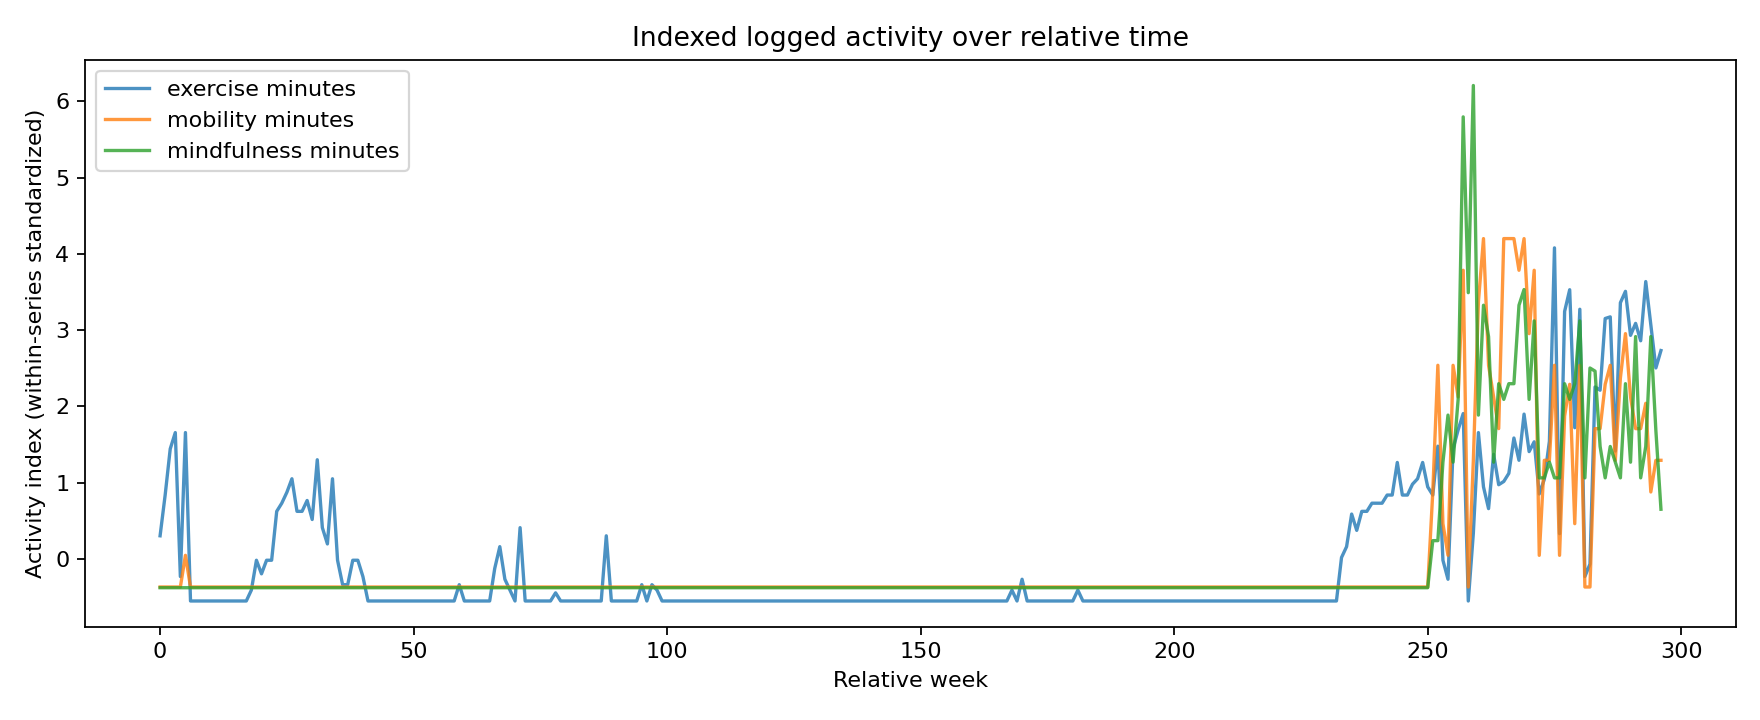

,model,MAE_index,scenario,development_rides
0,Class group mean,0.853006,Longer-class subset,315
1,Random forest,1.051526,Longer-class subset,315
2,Recent 28-day mean,0.566913,Longer-class subset,315
3,Ridge regression,1.360557,Longer-class subset,315
4,Training mean,0.946893,Longer-class subset,315
5,Class group mean,0.627599,Recent development window,204
6,Random forest,0.587474,Recent development window,204
7,Recent 28-day mean,0.582625,Recent development window,204
8,Ridge regression,0.566198,Recent development window,204
9,Training mean,0.724180,Recent development window,204


In [5]:
display(Image(filename=str(OUT / "activity_trends.png")))
display(pd.read_csv(OUT / "development_sensitivity.csv"))


## Interpretation and next step
Simple methods can outperform a nonlinear ensemble in a relevant comparison. Retain recent averages and regression in a prospective test with new observations and user-defined usefulness thresholds. A single-record-history case cannot establish general effectiveness, health improvement, churn reduction or revenue growth.

**Masking limitation:** fixed scaling and removal of direct identifiers reduce exposure but do not guarantee anonymity. Do not publish inverse keys or older raw exports. Updating current GitHub files does not purge prior commits.

Technical sources and preprocessing details are in docs/SOURCES.md and docs/METHODS.md. Outputs were captured by sequential execution of these Python cells without a Jupyter kernel in the build environment.